# 03. Quality, CSAT, Fair Agent Benchmarking & Repeat Contacts
**Input:** `data/processed/tickets_clean.csv`  
**Outputs:** Summary tables in `reports/tables/` and figures in `reports/figures/`

**Scope:**
- **Section F:** Reopen rates, CSAT averages across operational dimensions, CSAT survey response bias (55.1% missing), and First-Contact Resolution (FCR).
- **Section G:** Case-mix adjusted agent escalation rates (Rahul T vs. Karan B), non-escalated close speed vs. reopen rate trade-off, and agent category workload distribution.
- **Section H:** Repeat-contact surge (July to September), repeat rates by category, and top repeat-contact clients.

---
## F. Quality, Reopens, CSAT & First-Contact Resolution (FCR)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TAB_DIR = PROJECT_ROOT / "reports" / "tables"

df = pd.read_csv(PROCESSED_DIR / "tickets_clean.csv")
for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at", "week_start"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

# F1. Reopen Rate: Overall, Escalated vs Not, Category, Agent
print("=== F1. REOPEN RATE BREAKDOWN ===")
print(f"Overall Reopen Rate: {df['is_reopened'].mean()*100:.2f}% ({df['is_reopened'].sum()} / {len(df)})")

print("\nBy Escalation Status:")
f1_esc = df.groupby("is_escalated")["is_reopened"].agg(tickets="count", reopened="sum", reopen_rate_pct=lambda s: s.mean()*100)
f1_esc.index = ["Non-Escalated (0)", "Escalated (1)"]
display(f1_esc)

print("\nBy Category:")
f1_cat = df.groupby("category")["is_reopened"].agg(tickets="count", reopened="sum", reopen_rate_pct=lambda s: s.mean()*100).sort_values("reopen_rate_pct", ascending=False)
f1_cat.to_csv(TAB_DIR / "f1_reopen_by_category.csv")
display(f1_cat)

print("\nBy Agent:")
f1_agent = df.groupby("assigned_agent")["is_reopened"].agg(tickets="count", reopened="sum", reopen_rate_pct=lambda s: s.mean()*100).sort_values("reopen_rate_pct", ascending=False)
display(f1_agent)

# F2. CSAT Average Across Dimensions
print(f"\n=== F2. CSAT AVERAGE (Overall Mean: {df['csat_score'].mean():.3f}, Median: {df['csat_score'].median():.1f}) ===")
for grp in ["is_escalated", "eng_handoffs", "is_reopened", "assigned_agent"]:
    csat_tbl = df.groupby(grp)["csat_score"].agg(
        total_tickets="count",
        rated_tickets=lambda s: s.notna().sum(),
        mean_csat="mean",
        pct_low_csat_1_2=lambda s: (s.dropna() <= 2).mean() * 100 if s.notna().sum() > 0 else np.nan
    )
    if grp == "is_escalated":
        csat_tbl.index = ["Non-Escalated (0)", "Escalated (1)"]
    elif grp == "is_reopened":
        csat_tbl.index = ["Not Reopened (0)", "Reopened (1)"]
    print(f"\nCSAT by {grp}:")
    display(csat_tbl)

# F3. CSAT Response Rate & Responder Profile (Non-response bias check)
df["has_csat"] = df["csat_score"].notna().astype(int)
print(f"\n=== F3. CSAT SURVEY RESPONSE RATE (Overall: {df['has_csat'].mean()*100:.2f}% | Missing: {(1-df['has_csat'].mean())*100:.2f}%) ===")
resp_dfs = []
for dim in ["channel", "client_tier", "is_escalated", "is_reopened", "status"]:
    resp_tbl = df.groupby(dim)["has_csat"].agg(tickets="count", responded="sum", response_rate_pct=lambda s: s.mean()*100).reset_index()
    resp_tbl.rename(columns={dim: "segment_value"}, inplace=True)
    resp_tbl.insert(0, "dimension", dim)
    resp_dfs.append(resp_tbl)
    display(resp_tbl)

f3_resp_profile = pd.concat(resp_dfs, ignore_index=True)
f3_resp_profile.to_csv(TAB_DIR / "f3_csat_respondent_profile.csv", index=False)

# F4. First-Contact Resolution (FCR): Closed by L1, no escalation, no reopen
df["is_fcr"] = (
    (df["is_escalated"] == 0) &
    (df["is_reopened"] == 0) &
    (df["final_closed_at"].notna())
).astype(int)

print(f"\n=== F4. FIRST-CONTACT RESOLUTION (FCR) (Overall: {df['is_fcr'].mean()*100:.2f}% | {df['is_fcr'].sum()} / {len(df)}) ===")
f4_cat = df.groupby("category")["is_fcr"].agg(tickets="count", fcr_tickets="sum", fcr_rate_pct=lambda s: s.mean()*100).sort_values("fcr_rate_pct", ascending=False)
f4_cat.to_csv(TAB_DIR / "f4_fcr_by_category.csv")
display(f4_cat)


=== F1. REOPEN RATE BREAKDOWN ===
Overall Reopen Rate: 10.46% (151 / 1444)

By Escalation Status:


,tickets,reopened,reopen_rate_pct
Non-Escalated (0),958,96,10.02
Escalated (1),486,55,11.32



By Category:


,tickets,reopened,reopen_rate_pct
category,,,
Live tracking / GPS incorrect,228,35,15.35
Roster / booking not syncing,344,51,14.83
Employee address / geocode change,75,9,12.00
OTP / boarding issue,95,11,11.58
Report export failing,206,21,10.19
Billing / invoice discrepancy,88,7,7.95
Driver / vehicle compliance docs,57,4,7.02
Cab delay / no-show complaint,147,9,6.12
Login / access issue,100,2,2.00



By Agent:


,tickets,reopened,reopen_rate_pct
assigned_agent,,,
Karan B,217,64,29.49
Priya D,186,17,9.14
Neha P,171,14,8.19
Rahul T,151,12,7.95
Arjun K,178,14,7.87
Ananya R,189,13,6.88
Sneha M,176,9,5.11
Vikram S,176,8,4.55


... (12 outputs left out)

,tickets,responded,response_rate_pct
is_reopened,,,
0,1293,588,45.48
1,151,60,39.74


,tickets,responded,response_rate_pct
status,,,
Closed,1396,648,46.42
Open - with Engineering,19,0,0.00
Open - with L1,29,0,0.00



=== F4. FIRST-CONTACT RESOLUTION (FCR) (Overall: 59.00% | 852 / 1444) ===


,tickets,fcr_tickets,fcr_rate_pct
category,,,
Login / access issue,100,90,90.00
Driver / vehicle compliance docs,57,50,87.72
How-to / feature request,104,90,86.54
Cab delay / no-show complaint,147,124,84.35
Employee address / geocode change,75,55,73.33
Billing / invoice discrepancy,88,56,63.64
OTP / boarding issue,95,55,57.89
Report export failing,206,115,55.83
Roster / booking not syncing,344,134,38.95


---
## G. Fair Agent Benchmarking (Case-Mix Adjusted)
To avoid penalizing agents assigned harder ticket categories, we calculate each agent's **Expected Escalation Rate** given their exact category mix, compute the **Actual / Expected Ratio**, and compare non-escalated resolution speed against reopen rate.

In [2]:
# Category baseline escalation rates
cat_base_esc = df.groupby("category")["is_escalated"].mean().rename("cat_expected_esc_rate")
df_ag = df.merge(cat_base_esc, on="category", how="left")

# Non-escalated median resolution hours per agent
non_esc_speed = (
    df[df["is_escalated"] == 0]
    .groupby("assigned_agent")["resolution_hrs"]
    .median()
    .rename("non_esc_median_close_hrs")
)

# Master agent scorecard
agent_card = df_ag.groupby("assigned_agent").agg(
    total_tickets=("ticket_id", "count"),
    escalated_tickets=("is_escalated", "sum"),
    actual_esc_rate=("is_escalated", "mean"),
    expected_esc_rate=("cat_expected_esc_rate", "mean"),
    avoidable_esc_rate=("is_avoidable_esc", lambda s: s.sum() / max(df_ag.loc[s.index, "is_escalated"].sum(), 1)),
    reopen_rate=("is_reopened", "mean"),
    fcr_rate=("is_fcr", "mean"),
    mean_csat=("csat_score", "mean")
).reset_index()

agent_card["actual_vs_expected_ratio"] = agent_card["actual_esc_rate"] / agent_card["expected_esc_rate"]
agent_card = agent_card.merge(non_esc_speed, on="assigned_agent", how="left")

# Convert rates to percentages for presentation
agent_card_pct = agent_card.copy()
for c in ["actual_esc_rate", "expected_esc_rate", "avoidable_esc_rate", "reopen_rate", "fcr_rate"]:
    agent_card_pct[c] = agent_card_pct[c] * 100

agent_card_pct = agent_card_pct.sort_values("actual_vs_expected_ratio", ascending=False).reset_index(drop=True)
agent_card_pct.to_csv(TAB_DIR / "g1_agent_casemix_scorecard.csv", index=False)

print("=== G1. CASE-MIX ADJUSTED AGENT SCORECARD ===")
display(agent_card_pct)

print("\n=== G2. AGENT CATEGORY WORKLOAD MIX (% OF AGENT'S TICKETS) ===")
agent_cat_mix = pd.crosstab(df["assigned_agent"], df["category"], normalize="index") * 100
agent_cat_mix.to_csv(TAB_DIR / "g2_agent_category_mix.csv")
display(agent_cat_mix)

=== G1. CASE-MIX ADJUSTED AGENT SCORECARD ===


,assigned_agent,total_tickets,escalated_tickets,actual_esc_rate,expected_esc_rate,avoidable_esc_rate,reopen_rate,fcr_rate,mean_csat,actual_vs_expected_ratio,non_esc_median_close_hrs
0,Rahul T,151,93,61.59,34.39,75.27,7.95,35.76,3.52,1.79,12.09
1,Ananya R,189,76,40.21,34.13,47.37,6.88,56.08,3.84,1.18,11.73
2,Sneha M,176,61,34.66,33.08,49.18,5.11,60.80,3.72,1.05,15.40
3,Priya D,186,61,32.80,32.71,54.10,9.14,61.29,3.78,1.00,13.47
4,Arjun K,178,58,32.58,34.12,56.90,7.87,62.92,3.85,0.95,11.84
5,Vikram S,176,53,30.11,33.64,39.62,4.55,65.91,3.92,0.90,13.50
6,Neha P,171,49,28.65,33.33,61.22,8.19,65.50,3.94,0.86,12.23
7,Karan B,217,35,16.13,33.90,62.86,29.49,60.37,3.13,0.48,9.62



=== G2. AGENT CATEGORY WORKLOAD MIX (% OF AGENT'S TICKETS) ===


category,Billing / invoice discrepancy,Cab delay / no-show complaint,Driver / vehicle compliance docs,Employee address / geocode change,How-to / feature request,Live tracking / GPS incorrect,Login / access issue,OTP / boarding issue,Report export failing,Roster / booking not syncing
assigned_agent,,,,,,,,,,
Ananya R,7.41,11.11,3.17,4.23,7.41,17.99,6.88,6.88,11.11,23.81
Arjun K,7.87,10.67,2.81,6.18,6.18,15.73,5.06,8.99,14.04,22.47
Karan B,5.53,6.45,3.69,7.83,8.76,14.75,6.91,6.91,13.36,25.81
Neha P,5.85,10.53,4.09,4.68,6.43,15.20,7.02,7.02,18.13,21.05
Priya D,4.30,11.29,4.84,4.84,6.99,13.44,8.06,4.84,16.67,24.73
Rahul T,5.96,11.92,2.65,4.64,6.62,19.87,6.62,5.96,14.57,21.19
Sneha M,6.25,6.25,5.68,3.41,10.23,13.64,8.52,5.68,15.34,25.00
Vikram S,5.68,14.20,4.55,5.11,4.55,16.48,6.25,6.25,11.36,25.57


---
## H. Repeat-Contact Analysis (14-Day Window)
We examine the monthly trajectory of repeat contacts (same client and category within 14 days), identify high-repeat issue categories, and pinpoint the clients experiencing repeated friction.

In [3]:
print("=== H1. REPEAT-CONTACT RATE BY MONTH ===")
h1_month = df.groupby("month").agg(
    total_tickets=("ticket_id", "count"),
    repeat_tickets=("is_repeat_contact", "sum"),
    repeat_rate_pct=("is_repeat_contact", lambda s: s.mean() * 100)
).reset_index()
h1_month.to_csv(TAB_DIR / "h1_repeat_contacts_by_month.csv", index=False)
display(h1_month)

print("\n=== H2. REPEAT-CONTACT RATE BY CATEGORY ===")
h2_cat = df.groupby("category").agg(
    total_tickets=("ticket_id", "count"),
    repeat_tickets=("is_repeat_contact", "sum"),
    repeat_rate_pct=("is_repeat_contact", lambda s: s.mean() * 100)
).sort_values("repeat_rate_pct", ascending=False)
h2_cat.to_csv(TAB_DIR / "h2_repeat_contacts_by_category.csv")
display(h2_cat)

print("\n=== H3. TOP 10 CLIENTS BY REPEAT CONTACTS ===")
h3_client = df.groupby(["client_id", "client_name", "client_tier"]).agg(
    total_tickets=("ticket_id", "count"),
    repeat_tickets=("is_repeat_contact", "sum"),
    repeat_rate_pct=("is_repeat_contact", lambda s: s.mean() * 100)
).sort_values(["repeat_tickets", "repeat_rate_pct"], ascending=False).reset_index()
h3_client.to_csv(TAB_DIR / "h3_top_repeat_clients.csv", index=False)
display(h3_client.head(10))

=== H1. REPEAT-CONTACT RATE BY MONTH ===


,month,total_tickets,repeat_tickets,repeat_rate_pct
0,2026-07,390,58,14.87
1,2026-08,462,83,17.97
2,2026-09,592,147,24.83



=== H2. REPEAT-CONTACT RATE BY CATEGORY ===


,total_tickets,repeat_tickets,repeat_rate_pct
category,,,
Roster / booking not syncing,344,107,31.10
Live tracking / GPS incorrect,228,61,26.75
Cab delay / no-show complaint,147,27,18.37
Report export failing,206,33,16.02
How-to / feature request,104,12,11.54
Employee address / geocode change,75,7,9.33
Billing / invoice discrepancy,88,8,9.09
Login / access issue,100,9,9.00
OTP / boarding issue,95,7,7.37



=== H3. TOP 10 CLIENTS BY REPEAT CONTACTS ===


,client_id,client_name,client_tier,total_tickets,repeat_tickets,repeat_rate_pct
0,CL-010,Meridian Labs,Enterprise,37,18,48.65
1,CL-088,Evergreen Systems,Enterprise,24,10,41.67
2,CL-098,Horizon Infotech,Enterprise,25,10,40.00
3,CL-175,Orion Health,Enterprise,25,10,40.00
4,CL-114,Bluestone Financial,Enterprise,26,10,38.46
5,CL-153,Orion Financial,Enterprise,26,10,38.46
6,CL-113,Horizon Labs,Enterprise,22,9,40.91
7,CL-060,Summit Financial,Enterprise,26,9,34.62
8,CL-034,Silverline Analytics,Enterprise,27,9,33.33
9,CL-081,Harbor Tech Park,Enterprise,24,8,33.33


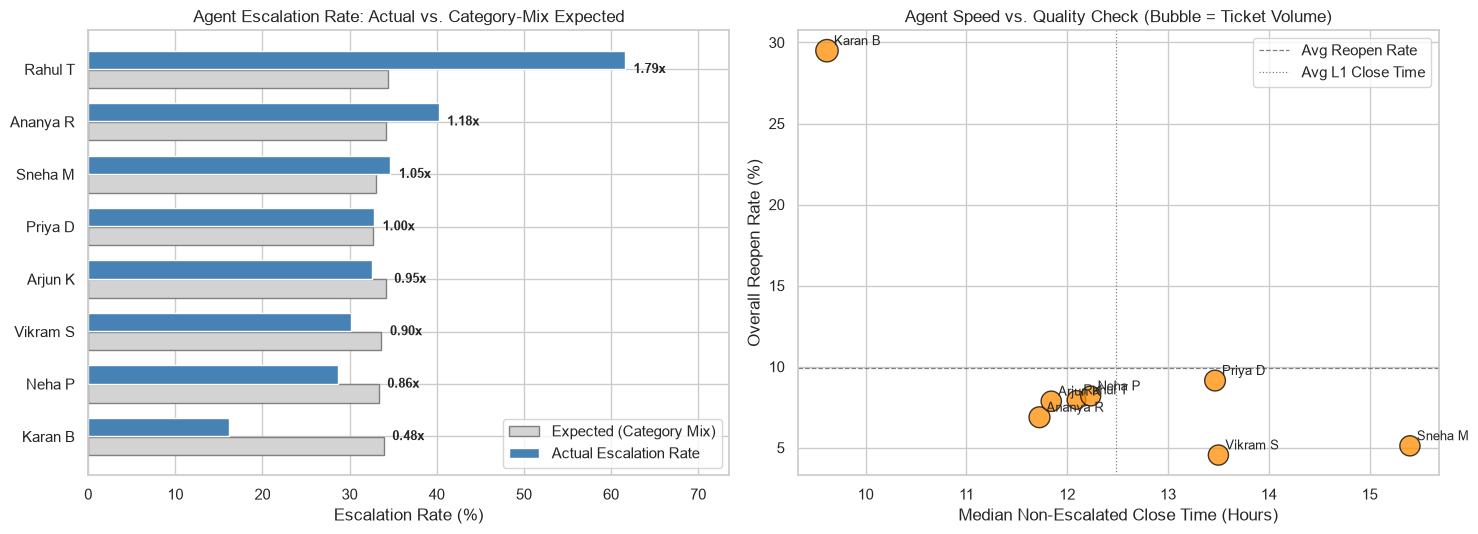

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Actual vs Expected Escalation Rate by Agent
ag_plot = agent_card_pct.sort_values("actual_vs_expected_ratio", ascending=True)
y_pos = np.arange(len(ag_plot))

axes[0].barh(y_pos - 0.18, ag_plot["expected_esc_rate"], height=0.35, label="Expected (Category Mix)", color="lightgray", edgecolor="gray")
axes[0].barh(y_pos + 0.18, ag_plot["actual_esc_rate"], height=0.35, label="Actual Escalation Rate", color="steelblue")

for idx, row in enumerate(ag_plot.itertuples()):
    axes[0].text(
        max(row.actual_esc_rate, row.expected_esc_rate) + 1.0,
        idx,
        f"{row.actual_vs_expected_ratio:.2f}x",
        va="center", fontsize=9, fontweight="bold"
    )

axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(ag_plot["assigned_agent"])
axes[0].set_xlim(0, ag_plot["actual_esc_rate"].max() + 12)
axes[0].set_xlabel("Escalation Rate (%)")
axes[0].set_title("Agent Escalation Rate: Actual vs. Category-Mix Expected")
axes[0].legend(loc="lower right")

# Plot 2: Speed vs Quality Trade-Off (Non-Escalated Median Close Hrs vs Reopen Rate)
axes[1].scatter(
    agent_card_pct["non_esc_median_close_hrs"],
    agent_card_pct["reopen_rate"],
    s=agent_card_pct["total_tickets"] * 1.2,
    alpha=0.75, color="darkorange", edgecolor="black"
)
for row in agent_card_pct.itertuples():
    axes[1].annotate(
        row.assigned_agent,
        (row.non_esc_median_close_hrs, row.reopen_rate),
        xytext=(5, 4), textcoords="offset points", fontsize=9
    )

axes[1].axhline(agent_card_pct["reopen_rate"].mean(), color="gray", linestyle="--", linewidth=0.9, label="Avg Reopen Rate")
axes[1].axvline(agent_card_pct["non_esc_median_close_hrs"].mean(), color="gray", linestyle=":", linewidth=0.9, label="Avg L1 Close Time")
axes[1].set_xlabel("Median Non-Escalated Close Time (Hours)")
axes[1].set_ylabel("Overall Reopen Rate (%)")
axes[1].set_title("Agent Speed vs. Quality Check (Bubble = Ticket Volume)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "fg_agent_benchmarking.png", dpi=150)
plt.show()